# Comparing tTEM with tTEM

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion import *
from anemone.forwards import *

In [2]:
gpu = torch.device('cpu')
cmdl = Resistivity.few_layers(torch.ones(3)*50., torch.ones(2)*20.)

In [3]:
from libaarhusxyz import GEX
import plog

In [4]:
gex = GEX("TX11_3x3_1_turn.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


In [5]:
x,y = gex.General['TxLoopPoint'][:, 0], gex.General['TxLoopPoint'][:, 1]
x,y = np.append(x, x[0]),               np.append(y, y[0])
z   = np.ones_like(x)*abs(gex.General['TxCoilPosition'][2])
tx  = Loop(x,y,z)
rx  = Receiver(*abs(gex.General['RxCoilPosition']))

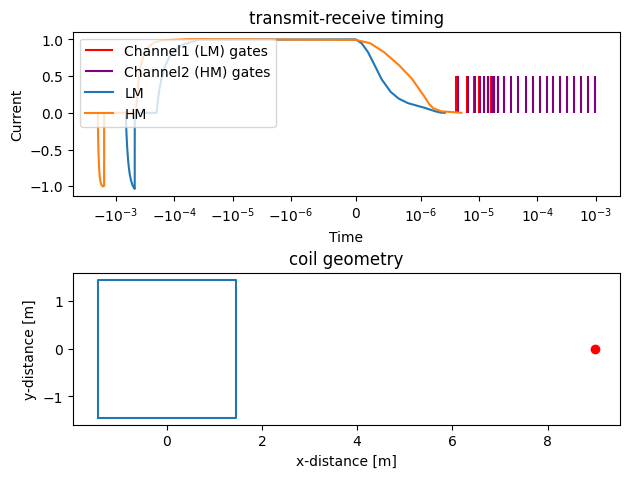

In [6]:
fig,axs=plt.subplots(2,1)
gex.plot(ax=axs[0])
axs[1].plot(tx.x, tx.y)
axs[1].plot(rx.x, rx.y, 'ro')
axs[1].set_aspect('equal')
axs[1].set_xlabel('x-distance [m]')
axs[1].set_ylabel('y-distance [m]')
axs[1].set_title('coil geometry')
axs[0].set_title('transmit-receive timing')
plt.tight_layout()

In [7]:
lmgates = torch.from_numpy(gex.gate_times('Channel1')[1:,0])
hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])

LMwv = Waveform(gex.General['WaveformLMPoint'][:, 0], gex.General['WaveformLMPoint'][:, 1])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

LFWR = logify_forward(Forward)
device = torch.device('cpu')
fwr  = LFWR(tx, rx, lmgates.to(device), LMwv, recfilters, tolerance=1e-6)
fwr += LFWR(tx, rx, hmgates.to(device), HMwv, recfilters, tolerance=1e-6)

C:\Users\au646858\AppData\Local\Temp\ipykernel_29464\4288314877.py:1: DeprecationWarning: Passing a string in to channel is deprecated and will be removed in a future release.
Please change the function call to 'gate_times' to use only an integer
  lmgates = torch.from_numpy(gex.gate_times('Channel1')[1:,0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_29464\4288314877.py:2: DeprecationWarning: Passing a string in to channel is deprecated and will be removed in a future release.
Please change the function call to 'gate_times' to use only an integer
  hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])


In [8]:
rho = torch.tensor([10, 200, 20])
thick1 = np.linspace(0.1, 5, 25)
thick = torch.tensor([5, 10])
data = fwr(rho, thick)
print(data.shape)

torch.Size([31])


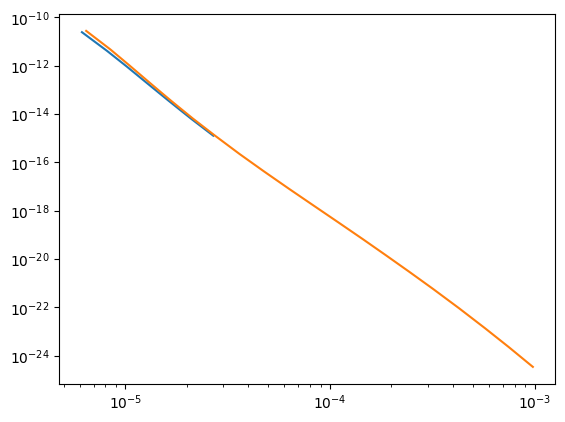

In [9]:
plt.figure()
plt.loglog(fwr.times[fwr.t1slc], 10**data[fwr.t1slc])
plt.loglog(fwr.times[fwr.t2slc], 10**data[fwr.t2slc])

In [15]:
class InvSensitivity(Tikhonov):
    def C_est(self, mvec):
        from torch.linalg import inv
        G = self.jacobian(mvec)
        C = inv(G.T @ torch.diag(self.recip_error_squared) @ G)
        return C
    
    def sensitivity_factor(self, mvec):
        C = self.C_est(mvec)
        diag = torch.sqrt(torch.diag(C))
        return torch.exp(diag)

    def plot_sensitivity_analysis(self, ax=None, x_offset=0, cbar=False):
        stdf, model = self.sensitivity_factor(self.model.vec), self.model
        import matplotlib.colors as colors
        cmap = colors.ListedColormap(['red', 'darkorange', 'yellow', 'aqua', 'blue'])
        norm = colors.BoundaryNorm(np.array([1., 1.2, 1.5, 2., 3., 4.]), cmap.N)    
        if ax is None:
            fig,ax = plt.subplots()

        dy = np.arange(len(model.vec)+1)
        tick_pos = (dy[:-1]+dy[1:])/2
        tick_lab = [f'$\\rho_{i+1}$' for i in range(len(model.values[0]))]
        tick_lab +=[f'thk$_{i+1}$' for i in range(len(model.values[1]))]
        dx = np.outer(np.ones_like(dy), np.array([-0.5, 0.5]))+x_offset
        dy = np.outer(dy, np.ones(2))
        val = stdf[:, None].cpu().numpy()
        val[np.isnan(val)] = 5.
        val[val>4] = 5
        pcm = ax.pcolormesh(dx, dy, val, cmap=cmap, norm=norm, edgecolor='k', linewidth=0.5)
        ax.set_yticks(tick_pos)
        ax.set_yticklabels(tick_lab)
        if cbar:
            import matplotlib.pyplot as plt
            plt.colorbar(pcm, ax=ax, label='sensitivity factor')
        return ax
    
# fastJac = fastjacobian(Tikhonov)


In [18]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
thick = torch.from_numpy(thick_stack)
lgs = [plog.Log(np.log10(rho), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]

C:\Users\au646858\AppData\Local\Temp\ipykernel_19464\3069985248.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  lgs = [plog.Log(np.log10(rho), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]


model 01	misfit: 0.73
model 02	misfit: 0.62
model 03	misfit: 0.78
model 04	misfit: 0.57
model 05	misfit: 0.66
model 06	misfit: 1.00
model 07	misfit: 0.62
model 08	misfit: 0.60
model 09	misfit: 0.80
model 10	misfit: 0.82
model 11	misfit: 0.79
model 12	misfit: 0.78
model 13	misfit: 0.76
model 14	misfit: 0.60
model 15	misfit: 0.58
model 16	misfit: 0.58
model 17	misfit: 0.56
model 18	misfit: 0.81
model 19	misfit: 0.66
model 20	misfit: 0.58
model 21	misfit: 0.54
model 22	misfit: 0.47
model 23	misfit: 0.68
model 24	misfit: 0.57
model 25	misfit: 0.49


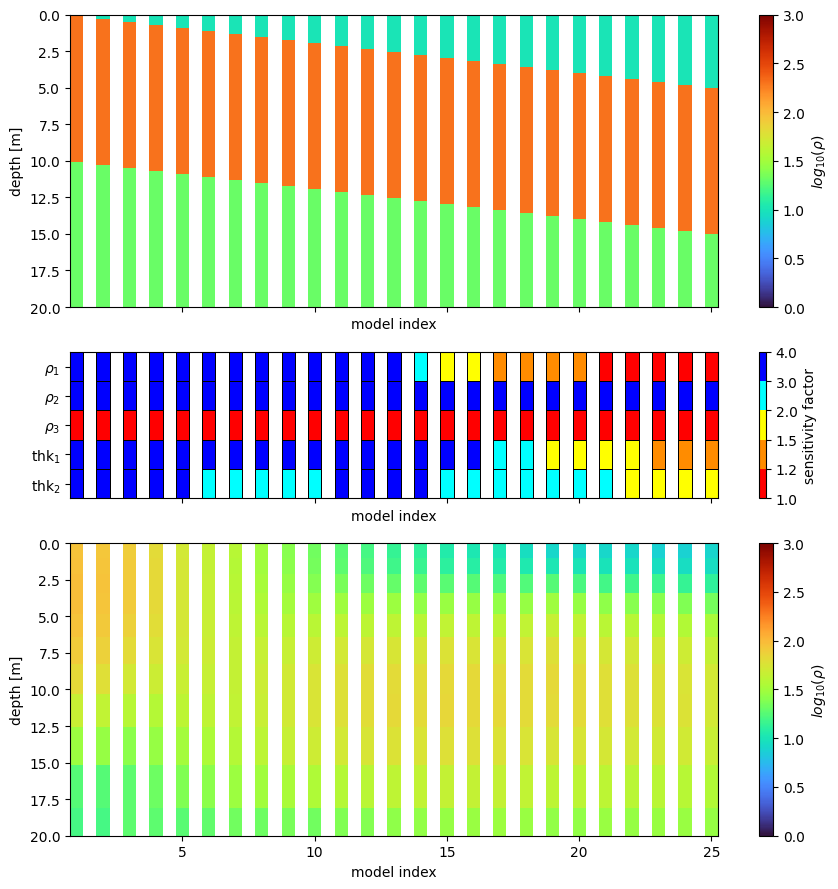

In [19]:
from anemone.experiment import compute_relstd

def silence(s):
    pass

cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(3,1, sharex=True, figsize=(9,9), height_ratios=[2,1,2])

lm_slice = fwr.t1slc
hm_slice = fwr.t2slc

for i,lg in enumerate(lgs):
    thick = torch.tensor([lg.depth_bot[0], 10])
    dbdt = 10**fwr(rho, thick)
    
    dbdt_err = compute_relstd(fwr.times, dbdt, current=10.)
    dbdt_err[hm_slice] = compute_relstd(fwr.times, dbdt, current=30.)[hm_slice]


#    inv = Inversion(dbdt, dbdt*dbdt_err, cmdl, fwr)
    m_true = LogResistivity.few_layers(rho, thick, device=gpu)

    ax,pcm=lg.plot(ax=axs[0], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

    inv = InvSensitivity(dbdt.log10(), (1+dbdt_err).log10(), m_true, fwr)
    inv.setup_matrices()
    inv.plot_sensitivity_analysis(ax=axs[1], x_offset=i*2, cbar=i==2)

    cmd_smooth = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.cumsum(torch.logspace(0,1.5,30), 0))
    
    dbdt_with_noise = torch.abs(dbdt + torch.randn(len(dbdt), device=gpu)*dbdt*dbdt_err/2)

    inv2 = InvSensitivity(dbdt_with_noise.log10(), (1.+dbdt_err).log10(), cmd_smooth.copy(), fwr, logger=silence)
    inv.vertical_smoothness = 1e-3
    inv.setup_matrices()
    rmod = inv2.invert(iter_cap=10)
    crho,thk = rmod.mod
    clg2 = plog.Log.standard(np.log10(crho.cpu().numpy()), np.cumsum(thk.cpu().numpy()), 'rho')
    ax,pcm=clg2.plot(ax=axs[2], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[2].set_ylim(20,0)
    print(f'model {i+1:02d}\tmisfit: {inv2.misfits[-1]:0.2f}')
    
for ax in axs:
    ax.set_xlabel('model index')
    ax.set_xticks(range(8, 51, 10))
    ax.set_xticklabels(range(5,26,5))
ax = axs[0]
ax.set_ylabel('depth [m]')
axs[2].set_ylabel('depth [m]')
axs[1].set_ylim(5,0)

plt.colorbar(pcm, ax=axs[0], label='$log_{10}\\left(\\rho\\right)$', format='%.1f')
plt.colorbar(pcm, ax=axs[2], label='$log_{10}\\left(\\rho\\right)$', format='%.1f')


plt.tight_layout()